In [1]:

import pandas as pd
import joblib

from pathlib import Path
from scipy.sparse import load_npz
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

import matplotlib.pyplot as plt
import seaborn as sns

# Path to the saved artifacts
MODEL_DIR = Path("../models")

# Load the trained model
nb_model = joblib.load(MODEL_DIR / "multinomial_nb_model.joblib")

# Load the TF-IDF test matrix and true labels
X_test_tfidf = load_npz(MODEL_DIR / "X_test_tfidf.npz")
y_test = pd.read_csv(MODEL_DIR / "y_test.csv").squeeze("columns")

# Verify the loaded data
print("Testing matrix shape:", X_test_tfidf.shape)
print("Testing labels shape:", y_test.shape)
print("Model loaded successfully!")


Testing matrix shape: (1034, 7591)
Testing labels shape: (1034,)
Model loaded successfully!


In [2]:

# Generate predictions for the test messages
y_pred = nb_model.predict(X_test_tfidf)

# Calculate evaluation metrics
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, pos_label=1)
recall = recall_score(y_test, y_pred, pos_label=1)
f1 = f1_score(y_test, y_pred, pos_label=1)

# Display the results
print(f"Accuracy:  {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1-score:  {f1:.4f}")


Accuracy:  0.9516
Precision: 1.0000
Recall:    0.6183
F1-score:  0.7642


In [3]:

# Detailed performance for both ham and spam
print(classification_report(
    y_test,
    y_pred,
    labels=[0, 1],
    target_names=["Ham", "Spam"],
    digits=4
))


              precision    recall  f1-score   support

         Ham     0.9475    1.0000    0.9731       903
        Spam     1.0000    0.6183    0.7642       131

    accuracy                         0.9516      1034
   macro avg     0.9738    0.8092    0.8686      1034
weighted avg     0.9542    0.9516    0.9466      1034



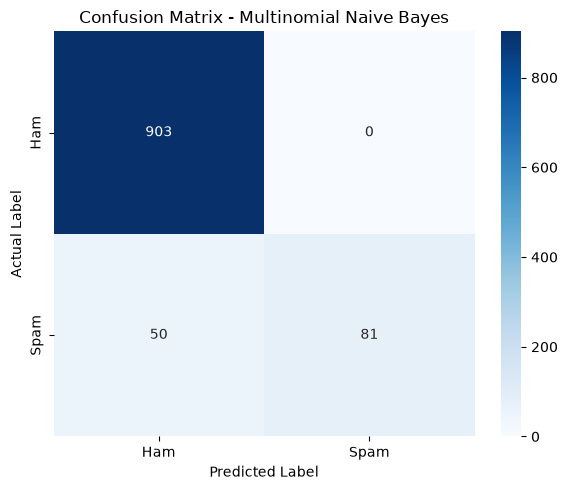

Confusion matrix:
[[903   0]
 [ 50  81]]


In [4]:

# Calculate the confusion matrix
cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

# Display the confusion matrix as a heatmap
plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Ham", "Spam"],
    yticklabels=["Ham", "Spam"]
)

plt.title("Confusion Matrix - Multinomial Naive Bayes")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.tight_layout()
plt.show()

print("Confusion matrix:")
print(cm)


In [5]:

# Get the model's estimated probability for the spam class (label 1)
spam_probabilities = nb_model.predict_proba(X_test_tfidf)[:, 1]

# Evaluate several decision thresholds
thresholds = [0.50, 0.40, 0.30, 0.20, 0.10]

results = []

for threshold in thresholds:
    # Predict spam when its estimated probability reaches the threshold
    threshold_predictions = (spam_probabilities >= threshold).astype(int)

    results.append({
        "Threshold": threshold,
        "Precision": precision_score(
            y_test, threshold_predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_test, threshold_predictions, zero_division=0
        ),
        "F1-score": f1_score(
            y_test, threshold_predictions, zero_division=0
        )
    })

threshold_results = pd.DataFrame(results)

threshold_results.round(4)


,Threshold,Precision,Recall,F1-score
0,0.5,1.0000,0.6183,0.7642
1,0.4,0.9888,0.6718,0.8000
2,0.3,0.9895,0.7176,0.8319
3,0.2,0.9817,0.8168,0.8917
4,0.1,0.8676,0.9008,0.8839


In [7]:

# Load the original test messages
test_df = pd.read_csv(Path("../data/processed") / "test.csv")

# Identify spam messages incorrectly predicted as ham
false_negative_mask = (y_test.to_numpy() == 1) & (y_pred == 0)

# Build a table of missed spam messages
missed_spam = test_df.loc[false_negative_mask, ["message", "label"]].copy()

print("Number of missed spam messages:", len(missed_spam))
missed_spam.head(10)


Number of missed spam messages: 50


,message,label
55,I am hot n horny and willing I live local to y...,1
79,Thanks for the Vote. Now sing along with the s...,1
95,Want explicit SEX in 30 secs? Ring 02073162414...,1
105,You will recieve your tone within the next 24h...,1
112,Send a logo 2 ur lover - 2 names joined by a h...,1
125,Congrats! 1 year special cinema pass for 2 is ...,1
160,"Hi babe its Jordan, how r u? Im home from abro...",1
168,Hi if ur lookin 4 saucy daytime fun wiv busty ...,1
174,TheMob>Hit the link to get a premium Pink Pant...,1
205,As a registered optin subscriber ur draw 4 å£1...,1


In [8]:

# Get the spam probabilities for every test message
spam_probabilities = nb_model.predict_proba(X_test_tfidf)[:, 1]

# Build a table of missed spam and their predicted spam probabilities
missed_spam_analysis = test_df.loc[
    false_negative_mask, ["message", "label"]
].copy()

missed_spam_analysis["spam_probability"] = spam_probabilities[
    false_negative_mask
]

# Show the messages with the lowest estimated spam probabilities
missed_spam_analysis = missed_spam_analysis.sort_values(
    "spam_probability"
)

missed_spam_analysis.head(10)


,message,label,spam_probability
437,Babe: U want me dont u baby! Im nasty and have...,1,0.005344
486,In The Simpsons Movie released in July 2007 na...,1,0.009583
801,Would you like to see my XXX pics they are so ...,1,0.009755
308,Hi its LUCY Hubby at meetins all day Fri & I w...,1,0.019859
544,Xmas & New Years Eve tickets are now on sale f...,1,0.038237
326,Missed call alert. These numbers called but le...,1,0.041717
160,"Hi babe its Jordan, how r u? Im home from abro...",1,0.046665
404,"FreeMsg Hey U, i just got 1 of these video/pic...",1,0.066572
456,Check Out Choose Your Babe Videos @ sms.shsex....,1,0.070335
168,Hi if ur lookin 4 saucy daytime fun wiv busty ...,1,0.079408


## Model Evaluation — Summary

### 1. Baseline Model
Evaluated the trained Multinomial Naive Bayes classifier on 1,034 held-out test messages.

### 2. Baseline Performance

- Accuracy: **95.16%**
- Spam precision: **100.00%**
- Spam recall: **61.83%**
- Spam F1-score: **76.42%**

### 3. Confusion Matrix

| Actual class | Predicted Ham | Predicted Spam |
|---|---:|---:|
| Ham | 903 | 0 |
| Spam | 50 | 81 |

The model correctly classified 903 ham messages and 81 spam messages. It missed 50 spam messages and produced no false positives on this test set.

### 4. Threshold Experiment

An exploratory threshold comparison showed that lowering the spam threshold increased recall. At a threshold of 0.20, spam precision was 98.17%, recall was 81.68%, and F1-score was 89.17% on the same test set.

These results are exploratory because the threshold was examined using test-set performance. A validation set should be used for threshold selection before final independent evaluation.

### 5. Error Analysis

Inspected false-negative spam messages and their predicted spam probabilities. Some missed messages used conversational language, event promotions, notification-style wording, or vocabulary that the model did not associate strongly with spam.

### Conclusion

The baseline model achieves high accuracy and precision but misses a notable proportion of spam messages at the default threshold. Further improvements should be evaluated using a validation set and a final held-out test set, with particular attention to spam recall, precision, and F1-score.